## Get all data ###

In [1]:
import pandas as pd

daily_return_df = pd.read_csv('sp500_joined_daily_returns_yahoo.csv')
daily_return_df.set_index('Date', inplace=True)

high_df = pd.read_csv('sp500_joined_high_yahoo.csv')
high_df.set_index('Date', inplace=True)

low_df = pd.read_csv('sp500_joined_low_yahoo.csv')
low_df.set_index('Date', inplace=True)

volume_df = pd.read_csv('sp500_joined_volume_yahoo.csv')
volume_df.set_index('Date', inplace=True)

windows = [5,10,20,40,60]

def calc_beta_error(daily,window):
    beta = daily.rolling(window=window, min_periods=3).cov(daily['SPY']).div(daily['SPY'].rolling(window=window, min_periods=3).var(), axis=0)
    return (daily - beta.mul(daily['SPY'], axis=0)) ** 2

# Random Forest #

## Get best windows for training results ##

In [2]:
concat_df = None
for w in windows:
    beta_error_df = calc_beta_error(daily_return_df,w)
    beta_error_df.columns = beta_error_df.columns + "_{0}".format(w)
    if concat_df is not None:
        concat_df = pd.concat([concat_df, beta_error_df], axis=1)
    else:
        concat_df = beta_error_df

min_windows_df = pd.DataFrame()
for ticker in daily_return_df.columns:
    prefix = ticker + '_'
    head = []
    for i in range(0,len(windows)):
        head.append(prefix + str(windows[i]))
    min_windows_df[ticker] = concat_df[head].idxmin(axis=1).str.replace(prefix,"").astype('float')

## Create feature and label set ##

In [3]:
daily_return_df.index = [pd.Timestamp(x) for x in daily_return_df.index]
min_windows_df.index = [pd.Timestamp(x) for x in min_windows_df.index]

In [4]:
## feature lehet a beta error az elmult 5 napban atlagosan az 5-os window-hoz, stb.
# volue*open vagy close lehet valid ertek
## volume
## Tobb fele rolling window
## RF parameterek allitasa
# beta error reszvenyenkent minden ablakra 
## ez lesz az X (+ egy szorast, meg egy arfolyamerteket min, max, volume)
# volatilis iszoszakok: beta ablak

In [15]:
X_df = pd.DataFrame({
    "mean_5": daily_return_df.rolling(window=5, min_periods=3).mean().stack(),
    "std_5": daily_return_df.rolling(window=5, min_periods=3).std().stack(),
    "std_10": daily_return_df.rolling(window=10, min_periods=3).std().stack(),
    "mean_10": daily_return_df.rolling(window=10, min_periods=3).mean().stack()})
X_df = X_df.dropna(axis = 0, how ='any')

mean_5     std_5    std_10   mean_10
2000-01-05 A    -0.056019  0.031004  0.031004 -0.056019
           AAPL  0.005545  0.060291  0.060291  0.005545
           ABC   0.018486  0.044461  0.044461  0.018486
           ABMD  0.001146  0.047968  0.047968  0.001146
           ABT  -0.002874  0.012485  0.012485 -0.002874
...                   ...       ...       ...       ...
2020-12-11 YUM   0.003112  0.004478  0.005667  0.000460
           ZBH  -0.007785  0.013950  0.016455 -0.004846
           ZBRA  0.002100  0.009516  0.011871 -0.000550
           ZION  0.000736  0.020238  0.020567  0.005039
           ZTS   0.003438  0.010264  0.010039 -0.001470

[2379422 rows x 4 columns]

In [19]:
# A holnapi Y-t a mai X-hez
Y_sr = min_windows_df.shift(-1).stack()
print(Y_sr.shape, X_df.shape)

comm_indices = [x for x in X_df.index if x in Y_sr.index]
Y_sr = Y_sr.loc[comm_indices]
X_df = X_df.loc[comm_indices]
print(Y_sr.shape, X_df.shape)

(2379415,) (2379422, 4)
(2378905,) (2378905, 4)


In [7]:
all_beta_5_df = calc_beta_error(daily_return_df, 5)
all_beta_10_df = calc_beta_error(daily_return_df, 10)
all_beta_20_df = calc_beta_error(daily_return_df, 20)
all_beta_40_df = calc_beta_error(daily_return_df, 40)
all_beta_60_df = calc_beta_error(daily_return_df, 60)

In [59]:
from sklearn.ensemble import RandomForestRegressor
from sklearn import metrics

models = []
for i in range(0,10):
    test_year = 2011 + i
    print(test_year)
    
    # 10 years of training + 1 years of testing
    train_index_sr = [x for x in X_df.index if  x[0] >= pd.Timestamp('{0}-01-01'.format(test_year-11)) and 
                                             x[0] < pd.Timestamp('{0}-01-01'.format(test_year))]
    test_index_sr = [x for x in X_df.index if x[0].year == test_year]
    
    test_X_df = X_df.loc[test_index_sr]
    train_X_df = X_df.loc[train_index_sr]
    train_Y_sr = Y_sr.loc[train_index_sr]
    test_y_sr = Y_sr.loc[test_index_sr]
    
    clf = RandomForestRegressor(n_estimators=100)
    clf.fit(train_X_df, train_Y_sr)
    Y_pred = clf.predict(test_X_df)
    
    # I need to shift because I want to use the previous value for every result
    predicted_Y = pd.DataFrame(Y_pred, index = test_X_df.index).unstack().shift(1)
    
    # Round to window sizes
    prev_window = -windows[0]
    for i in windows:
        # Between the two windows
        mask = (predicted_Y >= (prev_window + i)/2) & (predicted_Y <= i)
        predicted_Y[mask] = i
        
        # Window size = 5
        predicted_Y[(predicted_Y >= prev_window) & (~mask) & (predicted_Y <= i)] = abs(prev_window)
        prev_window = i
    
    # Window size = 60
    predicted_Y[predicted_Y >= windows[-1]] = windows[-1]
    predicted_Y = predicted_Y.droplevel(level=0, axis=1)
 
    sum_beta_errors_df = pd.DataFrame()
    sum_beta_errors_df.reset_index(drop = True)

    sum_beta_errors_df = all_beta_5_df.loc[predicted_Y.index][predicted_Y.columns][predicted_Y==5]
    sum_beta_errors_df = sum_beta_errors_df.add(all_beta_10_df.loc[predicted_Y.index][predicted_Y.columns][predicted_Y==10], fill_value=0)
    sum_beta_errors_df = sum_beta_errors_df.add(all_beta_20_df.loc[predicted_Y.index][predicted_Y.columns][predicted_Y==20], fill_value=0)
    sum_beta_errors_df = sum_beta_errors_df.add(all_beta_40_df.loc[predicted_Y.index][predicted_Y.columns][predicted_Y==40], fill_value=0)
    sum_beta_errors_df = sum_beta_errors_df.add(all_beta_60_df.loc[predicted_Y.index][predicted_Y.columns][predicted_Y==60], fill_value=0)
    models.append(sum_beta_errors_df)

2011
2012
2013
2014
2015
2016
2017
2018
2019
2020


<AxesSubplot:>

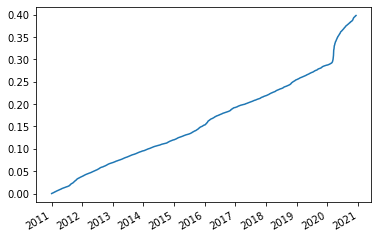

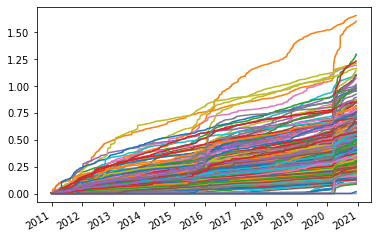

In [61]:
summa = pd.DataFrame(0.0,index=daily_return_df.index[daily_return_df.index.year > 2010],columns=daily_return_df.columns)
for model in models:
    summa = summa.add(model,fill_value=0)
summa.mean(axis=1).cumsum().plot()
summa.cumsum().plot(legend=False)

In [63]:
summa.to_csv("RF_100_mean_5_std_5_std_10_mean_10")

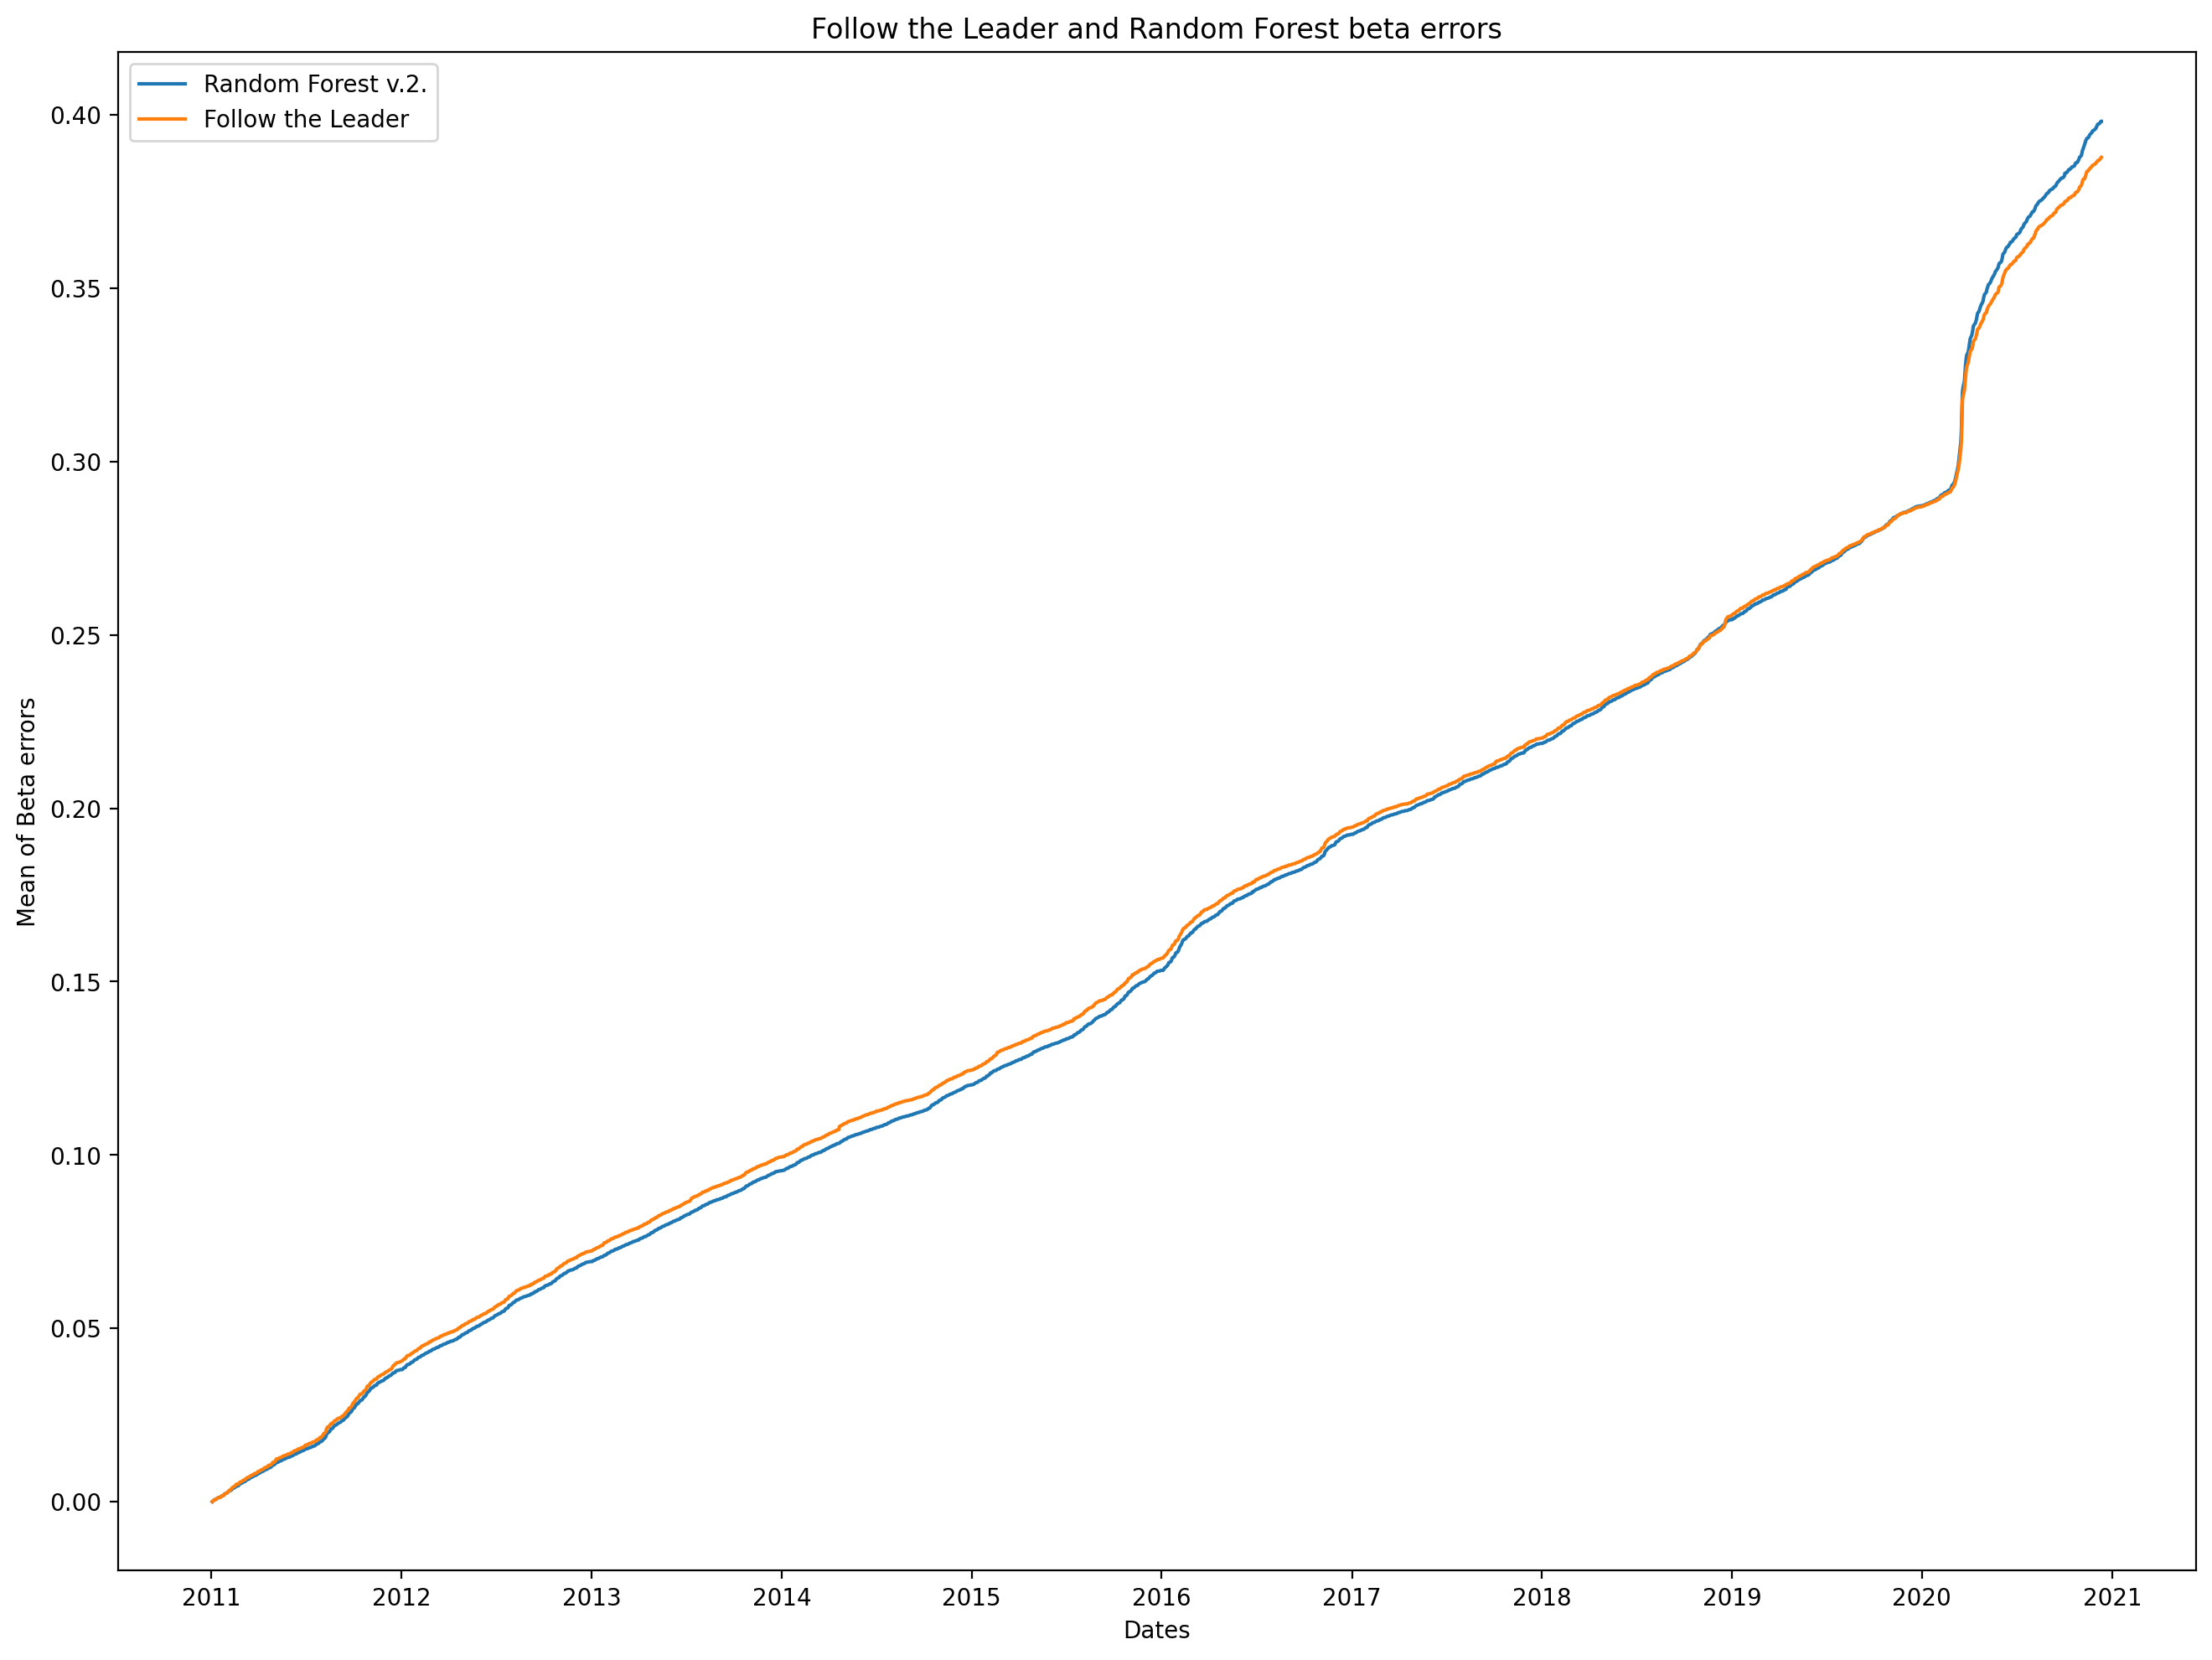

In [68]:
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

figure(num=None, figsize=(16, 12), dpi=200, facecolor='w', edgecolor='k')

FTL_result = pd.read_csv('FTL_results.csv')
FTL_result.set_index('Date', inplace=True)
FTL_result.index = [pd.Timestamp(x) for x in FTL_result.index]
FTL_result = FTL_result.loc[[x for x in FTL_result.index if x.year >= 2011]]

plt.plot(summa.mean(axis=1).cumsum(), label = "Random Forest v.2.")
plt.plot(FTL_result.mean(axis=1).cumsum(), label = "Follow the Leader")


plt.xlabel('Dates')
plt.ylabel('Mean of Beta errors')
plt.title('Follow the Leader and Random Forest beta errors')
plt.legend()

## Analyse tree ##

<BarContainer object of 4 artists>

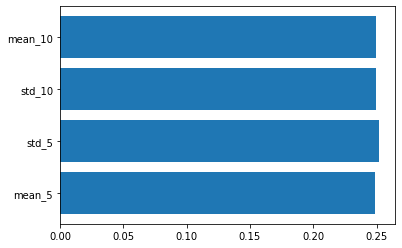

In [89]:
feature_list = ["mean_5", "std_5", "std_10", "mean_10"]
plt.barh(feature_list, clf.feature_importances_)

In [98]:
[estimator.tree_.max_depth for estimator in clf.estimators_]

[99,
 100,
 111,
 108,
 94,
 118,
 96,
 115,
 122,
 115,
 99,
 108,
 104,
 106,
 97,
 127,
 98,
 108,
 108,
 129,
 105,
 102,
 87,
 88,
 102,
 97,
 100,
 96,
 102,
 120,
 130,
 90,
 115,
 107,
 98,
 100,
 95,
 101,
 107,
 115,
 105,
 98,
 104,
 98,
 114,
 96,
 107,
 113,
 86,
 93,
 119,
 94,
 111,
 103,
 111,
 135,
 117,
 105,
 90,
 115,
 97,
 132,
 94,
 104,
 113,
 101,
 104,
 106,
 106,
 105,
 96,
 106,
 92,
 101,
 103,
 94,
 116,
 101,
 103,
 96,
 101,
 99,
 97,
 86,
 103,
 99,
 119,
 97,
 106,
 107,
 109,
 97,
 108,
 110,
 92,
 132,
 107,
 89,
 113,
 105]